# 07 — Class Imbalance: Class Weighting, Random Oversampling and SMOTENC
### Telco Customer Churn Prediction

**Question.** Only 26.7% of training customers churned. Does correcting this imbalance during training — by weighting or by resampling — improve the model's *useful* performance? Higher minority-class recall at the default threshold is not enough to count as an improvement.

**Why this needs care.** Changing the class balance shifts predicted probabilities upward. That raises recall at a fixed 0.5 threshold, but the same recall can be obtained by simply lowering the threshold of an unweighted model. A real improvement must therefore appear in **threshold-independent** measures (PR-AUC, ROC-AUC) or at **matched recall**, without damaging probability **calibration** (Brier score), which the cost-based threshold in notebook 08 relies on.

**Design:**
- **Two models:** Logistic Regression (the most interpretable candidate) and HistGradientBoosting (a strong non-linear learner). Same grids, folds and preprocessing as notebooks 01 and 04.
- **Four strategies for each:**

| Strategy | What changes | Where it acts |
|---|---|---|
| None (baseline) | Nothing | — |
| Class weighting | Churners get a larger weight in the training loss (`class_weight='balanced'`) | Loss function |
| Random oversampling | Churners are duplicated at random until the classes are balanced | Training rows |
| SMOTENC | Synthetic churners are created between neighbouring churners | Training rows |

- **Resampling is applied only inside training folds.** The sampler is the first step of an `imblearn` `Pipeline`, which applies it only during `fit`. Inside nested CV, every inner and outer validation fold, and of course the test set, keeps its real class distribution.


**Shared protocol** (identical to notebooks 01–06):
- Same training set (3,944 customers) and same 5 stratified folds (`random_state = 34`).
- Same preprocessing (`FINAL_PREP_CONFIG` from notebook 00): binary add-ons, one-hot `InternetService` and `Contract`, binary `Dependents`/`PaperlessBilling`, standardised `log(1 + tenure)` and `MonthlyCharges`.
- Same tuning procedure: **nested cross-validation** (inner 5-fold grid search, outer 5-fold evaluation), scored by PR-AUC.
- Unweighted classes; class imbalance is handled at the decision threshold (notebook 08) and examined in notebook 07.
- The test set is **not used**. The nested out-of-fold predictions saved at the end are used for comparison and threshold selection in notebook 08.

## 1. How SMOTE and SMOTENC Work

**SMOTE** (Synthetic Minority Over-sampling Technique) creates a synthetic minority example by:
1. picking a churner;
2. picking one of its *k* nearest churner neighbours (default *k* = 5);
3. placing a new point at a random position on the line between them.

This works for continuous features, but on **one-hot encoded categories** it produces fractional values (e.g. "0.4 of a two-year contract") that correspond to no real customer.

**SMOTENC** (SMOTE for Nominal and Continuous features) solves this:
- continuous features (`tenure`, `MonthlyCharges`) are interpolated as in SMOTE;
- each categorical feature of the synthetic row takes the **most frequent category among the neighbours**;
- distances between categories use a special penalty term, so neighbours are found on the mixed data directly.

SMOTENC is therefore applied to the **raw** columns, *before* encoding. The remaining preprocessing then runs on the resampled training fold exactly as for the other models.

## 2. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler, SMOTENC
import imblearn
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

from src.data_preprocessing import (ADDON_FEATURES, CATEGORICAL_FEATURES, FINAL_PREP_CONFIG, RANDOM_STATE,
                                    load_raw_data, split_train_test)
from src.evaluation import pick_threshold, run_nested_cv, save_results, threshold_table
from src.visualization import plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
df = load_raw_data()
X_train, X_test, y_train, y_test = split_train_test(df)
del X_test, y_test   # the test set is not used in this notebook
print(f"imbalanced-learn {imblearn.__version__} | training set: {len(X_train):,} customers")

imbalanced-learn 0.14.2 | training set: 3,944 customers


## 3. The Original Training Distribution and What SMOTENC Produces

For illustration only, SMOTENC is applied once to the whole training set. In the experiments it is applied separately inside each training fold. The check verifies whether the synthetic customers respect the structural rule from notebook 00, i.e. that *'No internet service' appears in the add-on columns exactly when `InternetService = 'No'`*.

In [2]:
smotenc_demo = SMOTENC(categorical_features=CATEGORICAL_FEATURES, random_state=RANDOM_STATE)
X_res, y_res = smotenc_demo.fit_resample(X_train, y_train)
distribution = pd.DataFrame({"original training set": y_train.value_counts().sort_index(),
                             "after SMOTENC (illustration)": pd.Series(y_res).value_counts().sort_index()})
distribution.index = ["No churn (0)", "Churn (1)"]
display(distribution)

synthetic = X_res.iloc[len(X_train):]
no_internet = synthetic["InternetService"].eq("No")
structurally_invalid = ((no_internet & synthetic[ADDON_FEATURES].ne("No internet service").any(axis=1))
                        | (~no_internet & synthetic[ADDON_FEATURES].eq("No internet service").any(axis=1)))
print(f"Synthetic churners created: {len(synthetic):,}")
print(f"Structurally invalid synthetic rows: {int(structurally_invalid.sum())}")
print(f"Synthetic rows with non-integer tenure: {int((synthetic['tenure'] % 1 != 0).sum())}")
display(synthetic.head())

,original training set,after SMOTENC (illustration)
No churn (0),2891,2891
Churn (1),1053,2891


Synthetic churners created: 1,838
Structurally invalid synthetic rows: 0
Synthetic rows with non-integer tenure: 0


,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges
3944,No,53,No,No,Fiber optic,Yes,No,Month-to-month,Yes,95.257064
3945,No,2,No,No,DSL,No,No,Month-to-month,Yes,45.265327
3946,Yes,4,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,Yes,20.745192
3947,No,44,Yes,Yes,DSL,No,Yes,One year,Yes,61.910733
3948,No,1,No,No,Fiber optic,No,No,Month-to-month,Yes,89.958987


**Interpretation.**
- The training set has 2,891 non-churners and 1,053 churners. SMOTENC creates **1,838 synthetic churners** to balance the classes.
- **None of the synthetic rows violate the structural rule.** Because SMOTENC chooses each category by majority vote among similar churners, and similar churners share the same internet-service status, the add-on values stay consistent.
- Tenure stays a whole number of months.
- Interpolated `MonthlyCharges` values have more decimals than real bills (e.g. 95.257064), which is harmless for the model.

So SMOTENC produces plausible customers. Whether they *help* is the next question.

## 4. Nested Cross-Validation of the Eight Configurations

Each of the 2 models × 4 strategies is tuned and evaluated with the same nested CV as notebooks 01–06. Class weighting is set on the estimator; samplers are inserted into the pipeline.

In [3]:
MODELS = {
    "Logistic Regression": (LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE),
                            {"model__C": [0.001, 0.01, 0.1, 1, 10], "model__l1_ratio": [0.0, 1.0]}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE),
                             {"model__learning_rate": [0.01, 0.03, 0.1], "model__max_leaf_nodes": [4, 7, 15],
                              "model__min_samples_leaf": [20, 50], "model__l2_regularization": [0.0, 1.0]}),
}
STRATEGIES = {
    "None": dict(weight=None, sampler=None),
    "Class weighting": dict(weight="balanced", sampler=None),
    "Random oversampling": dict(weight=None, sampler=RandomOverSampler(random_state=RANDOM_STATE)),
    "SMOTENC": dict(weight=None, sampler=SMOTENC(categorical_features=CATEGORICAL_FEATURES, random_state=RANDOM_STATE)),
}

imbalance_results = {}
for model_name, (estimator, grid) in MODELS.items():
    for strategy, cfg in STRATEGIES.items():
        est = clone(estimator).set_params(class_weight=cfg["weight"])
        res = run_nested_cv(est, grid, X_train, y_train, FINAL_PREP_CONFIG, sampler=cfg["sampler"])
        imbalance_results[(model_name, strategy)] = res
        print(f"{model_name:22s} | {strategy:20s} | {res['seconds']:6.1f} s | "
              f"PR-AUC {res['folds']['pr_auc'].mean():.4f}")

Logistic Regression    | None                 |    5.2 s | PR-AUC 0.6661


Logistic Regression    | Class weighting      |    1.1 s | PR-AUC 0.6662


Logistic Regression    | Random oversampling  |    1.8 s | PR-AUC 0.6645


Logistic Regression    | SMOTENC              |    4.2 s | PR-AUC 0.6641


HistGradientBoosting   | None                 |   10.0 s | PR-AUC 0.6567


HistGradientBoosting   | Class weighting      |   12.3 s | PR-AUC 0.6560


HistGradientBoosting   | Random oversampling  |   11.7 s | PR-AUC 0.6555


HistGradientBoosting   | SMOTENC              |   19.9 s | PR-AUC 0.6578


## 5. Results

### 5.1 Threshold-independent metrics and the 0.5-threshold illusion

In [4]:
rows = []
for (model_name, strategy), res in imbalance_results.items():
    f = res["folds"]
    rows.append({"model": model_name, "strategy": strategy,
                 "PR-AUC": f["pr_auc"].mean(), "PR-AUC std": f["pr_auc"].std(ddof=0),
                 "ROC-AUC": f["roc_auc"].mean(), "Brier score": f["brier"].mean(), "Log loss": f["log_loss"].mean(),
                 "mean predicted probability": res["oof"].mean(),
                 "recall @0.5": f["recall"].mean(), "precision @0.5": f["precision"].mean(), "F1 @0.5": f["f1"].mean()})
imbalance_table = pd.DataFrame(rows).set_index(["model", "strategy"])
display(imbalance_table.round(4))
print(f"Actual training churn rate: {y_train.mean():.4f}")

PR-AUC  PR-AUC std  ROC-AUC  \
model                strategy                                           
Logistic Regression  None                 0.6661      0.0273   0.8461   
                     Class weighting      0.6662      0.0272   0.8465   
                     Random oversampling  0.6645      0.0282   0.8444   
                     SMOTENC              0.6641      0.0271   0.8456   
HistGradientBoosting None                 0.6567      0.0151   0.8438   
                     Class weighting      0.6560      0.0253   0.8433   
                     Random oversampling  0.6555      0.0211   0.8427   
                     SMOTENC              0.6578      0.0175   0.8421   

                                          Brier score  Log loss  \
model                strategy                                     
Logistic Regression  None                      0.1362    0.4186   
                     Class weighting           0.1649    0.4911   
                     Random oversampling       0.1650    0.4933   
                     SMOTENC                   0.1642    0.4911   
HistGradientBoosting None                      0.1365    0.4188   
                     Class weighting           0.1647    0.4904   
                     Random oversampling       0.1638    0.4873   
                     SMOTENC                   0.1634    0.4843   

                                          mean predicted probability  \
model                strategy                                          
Logistic Regression  None                                     0.2674   
                     Class weighting                          0.4153   
                     Random oversampling                      0.4181   
                     SMOTENC                                  0.4125   
HistGradientBoosting None                                     0.2666   
                     Class weighting                          0.4098   
                     Random oversampling                      0.4052   
                     SMOTENC                                  0.4013   

                                          recall @0.5  precision @0.5  F1 @0.5  
model                strategy                                                   
Logistic Regression  None                      0.5090          0.6643   0.5732  
                     Class weighting           0.8091          0.5209   0.6329  
                     Random oversampling       0.8043          0.5186   0.6295  
                     SMOTENC                   0.7996          0.5189   0.6285  
HistGradientBoosting None                      0.5185          0.6450   0.5732  
                     Class weighting           0.7892          0.5221   0.6282  
                     Random oversampling       0.7939          0.5219   0.6292  
                     SMOTENC                   0.7910          0.5223   0.6288

Actual training churn rate: 0.2670


### 5.2 Paired fold differences and matched-recall comparison

PR-AUC differences are computed fold by fold against the *None* strategy (same folds, so the comparison is paired). Threshold-dependent metrics are then compared at **matched recall**: for each configuration, the threshold on its own nested OOF probabilities that gives the highest precision while keeping recall ≥ 0.80. If resampling only shifts probabilities, the precision at matched recall should be the same.

In [5]:
paired_rows, matched_rows = [], []
monthly = X_train["MonthlyCharges"].to_numpy()
for (model_name, strategy), res in imbalance_results.items():
    diff = res["folds"]["pr_auc"] - imbalance_results[(model_name, "None")]["folds"]["pr_auc"]
    paired_rows.append({"model": model_name, "strategy": strategy, "mean PR-AUC difference vs None": diff.mean(),
                        "SD of difference": diff.std(ddof=0), "folds better than None": int((diff > 0).sum())})
    tbl = threshold_table(y_train, res["oof"], monthly)
    t = pick_threshold(tbl, "precision", mask=tbl["recall"] >= 0.80)
    matched_rows.append({"model": model_name, "strategy": strategy, "threshold for recall >= 0.80": t,
                         "recall": tbl.loc[t, "recall"], "precision": tbl.loc[t, "precision"], "F1": tbl.loc[t, "f1"],
                         "min expected cost (illustrative)": tbl["total expected cost"].min()})
paired_table = pd.DataFrame(paired_rows).set_index(["model", "strategy"])
matched_table = pd.DataFrame(matched_rows).set_index(["model", "strategy"])
display(paired_table.round(4))
display(matched_table.round(4))

mean PR-AUC difference vs None  \
model                strategy                                              
Logistic Regression  None                                         0.0000   
                     Class weighting                              0.0001   
                     Random oversampling                         -0.0016   
                     SMOTENC                                     -0.0020   
HistGradientBoosting None                                         0.0000   
                     Class weighting                             -0.0007   
                     Random oversampling                         -0.0012   
                     SMOTENC                                      0.0011   

                                          SD of difference  \
model                strategy                                
Logistic Regression  None                           0.0000   
                     Class weighting                0.0012   
                     Random oversampling            0.0025   
                     SMOTENC                        0.0035   
HistGradientBoosting None                           0.0000   
                     Class weighting                0.0110   
                     Random oversampling            0.0068   
                     SMOTENC                        0.0065   

                                          folds better than None  
model                strategy                                     
Logistic Regression  None                                      0  
                     Class weighting                           2  
                     Random oversampling                       1  
                     SMOTENC                                   2  
HistGradientBoosting None                                      0  
                     Class weighting                           1  
                     Random oversampling                       1  
                     SMOTENC                                   2

threshold for recall >= 0.80  \
model                strategy                                            
Logistic Regression  None                                         0.27   
                     Class weighting                              0.50   
                     Random oversampling                          0.50   
                     SMOTENC                                      0.49   
HistGradientBoosting None                                         0.25   
                     Class weighting                              0.48   
                     Random oversampling                          0.49   
                     SMOTENC                                      0.48   

                                          recall  precision      F1  \
model                strategy                                         
Logistic Regression  None                 0.8063     0.5186  0.6312   
                     Class weighting      0.8091     0.5192  0.6325   
                     Random oversampling  0.8044     0.5168  0.6293   
                     SMOTENC              0.8101     0.5145  0.6293   
HistGradientBoosting None                 0.8025     0.5115  0.6248   
                     Class weighting      0.8053     0.5133  0.6270   
                     Random oversampling  0.8006     0.5162  0.6277   
                     SMOTENC              0.8082     0.5145  0.6287   

                                          min expected cost (illustrative)  
model                strategy                                               
Logistic Regression  None                                        827495.10  
                     Class weighting                             827023.11  
                     Random oversampling                         828229.90  
                     SMOTENC                                     827686.80  
HistGradientBoosting None                                        826576.44  
                     Class weighting                             827525.52  
                     Random oversampling                         828399.11  
                     SMOTENC                                     827505.07

### 5.3 Calibration

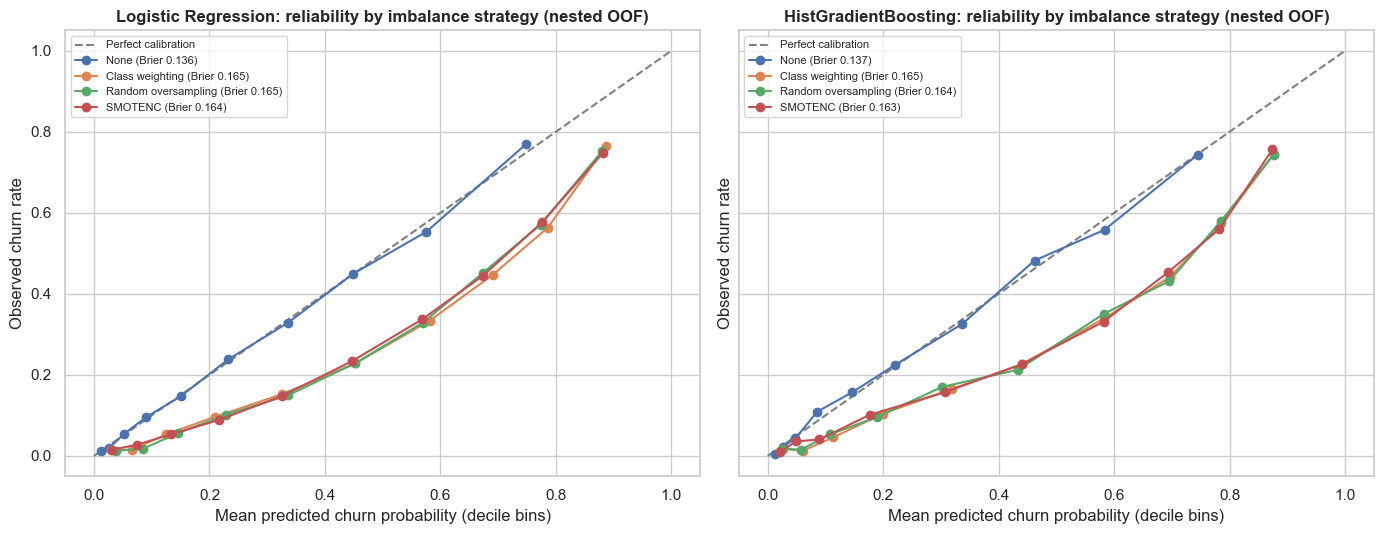

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, model_name in zip(axes, MODELS):
    plot_reliability(ax, y_train, {s: imbalance_results[(model_name, s)]["oof"] for s in STRATEGIES},
                     f"{model_name}: reliability by imbalance strategy (nested OOF)")
plt.tight_layout()
save_figure(fig, "07_calibration_by_strategy")
plt.show()

**Interpretation**

**1. No strategy improves ranking.**
- Logistic Regression: PR-AUC differences vs no correction are +0.0001 (weighting), −0.0016 (random oversampling) and −0.0020 (SMOTENC), each better in at most 2 of 5 folds.
- HistGradientBoosting: −0.0007, −0.0012 and +0.0011, also better in at most 2 folds.
- All differences are far below the fold-to-fold SD (0.015–0.027). ROC-AUC is equally unchanged.

**2. Recall at 0.5 rises from about 0.51 to about 0.80, but this is an illusion of the fixed threshold.**
- Every correction pushes predicted probabilities upward: the mean predicted probability rises from 0.267 (equal to the real churn rate) to about 0.40–0.42, so more customers cross 0.5.
- **At matched recall (≥ 0.80), precision is the same for every strategy** (Logistic Regression 0.515–0.519; HistGradientBoosting 0.512–0.516). The unweighted model reaches the same operating point by lowering its threshold to 0.27, whereas the resampled models need about 0.49.

**3. Calibration gets worse.**
- The Brier score rises from 0.136 to 0.163–0.165, and log loss from 0.419 to 0.48–0.49.
- The reliability curves of all corrected models lie well below the diagonal: they over-predict churn. Their scores would have to be recalibrated before they could be read as probabilities or used in the expected-cost calculation.

**Why SMOTENC fails to help here**
- The imbalance (about 1 : 2.7) is moderate, so the minority class is not too small to learn from.
- Synthetic rows add no new information: they are interpolations of existing churners.
- For probabilistic models trained with log-loss, rebalancing mainly shifts the intercept or score scale, which threshold choice already handles.

## 6. Decision and Conclusion

**Decision: no class-imbalance correction.** All models are trained on the original class distribution, and imbalance is handled by choosing the threshold on calibrated probabilities (notebook 08).

| Criterion | Class weighting | Random oversampling | SMOTENC |
|---|---|---|---|
| Ranking (PR-AUC, ROC-AUC) | No gain | No gain | No gain |
| Precision at matched recall | Same | Same | Same |
| Calibration | Worse | Worse | Worse |
| Added complexity | Low | Low (extra package) | Higher (extra package, slower fits, synthetic data to justify) |

SMOTENC would only be worth reconsidering with a much rarer positive class, or with a model that cannot output probabilities and therefore cannot have its threshold moved.

In [7]:
save_results("07_imbalance_comparison", {
    "table": imbalance_table, "paired": paired_table, "matched": matched_table,
    "oof": {k: v["oof"] for k, v in imbalance_results.items()},
    "folds": {k: v["folds"] for k, v in imbalance_results.items()},
    "y_index": y_train.index.to_numpy(),
})
print("Saved reports/cv_results/07_imbalance_comparison.joblib")

Saved reports/cv_results/07_imbalance_comparison.joblib
